<a href="https://colab.research.google.com/github/Bosco-bit/Bosco-bit-DataScience-GenAI-Submissions/blob/main/7_01_Exploratory_Data_Analysis_Salary_Student_Completed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![](https://drive.google.com/uc?export=view&id=1xqQczl0FG-qtNA2_WQYuWePW9oU8irqJ)

# 2.05 Exploratory Data Analysis (EDA)
In this exercise, you will explore a salary dataset (`EDA-DP.csv`) from the Week 7 Seminar Resources on myWBS. Work through the tasks in order. The setup cell below imports the libraries and allows you to upload the dataset.

In [22]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from google.colab import files
upload = files.upload()

Saving EDA-DP.csv to EDA-DP (1).csv


**Task 1 — Load the data.** Read `EDA-DP.csv` into a pandas DataFrame and display the first few rows.

In [35]:
df = pd.read_csv('EDA-DP.csv')
df.head()

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2024,SE,FT,AI Engineer,202730,USD,202730,US,0,US,M
1,2024,SE,FT,AI Engineer,92118,USD,92118,US,0,US,M
2,2024,SE,FT,Data Engineer,130500,USD,130500,US,0,US,M
3,2024,SE,FT,Data Engineer,96000,USD,96000,US,0,US,M
4,2024,SE,FT,Machine Learning Engineer,190000,USD,190000,US,0,US,M


**Task 2 — Dataset size.** Find the number of rows and columns in the dataset.

In [24]:
print(f"The dataset has {df.shape[0]} rows and {df.shape[1]} columns.")

The dataset has 16534 rows and 11 columns.


**Task 3 — Dataset structure.** Inspect the column names, data types, and number of non-missing values.

In [25]:
print("Column names, data types and non-missing values:\n")
df.info()

Column names, data types and non-missing values:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16534 entries, 0 to 16533
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   work_year           16534 non-null  int64 
 1   experience_level    16534 non-null  object
 2   employment_type     16534 non-null  object
 3   job_title           16534 non-null  object
 4   salary              16534 non-null  int64 
 5   salary_currency     16534 non-null  object
 6   salary_in_usd       16534 non-null  int64 
 7   employee_residence  16534 non-null  object
 8   remote_ratio        16534 non-null  int64 
 9   company_location    16534 non-null  object
 10  company_size        16534 non-null  object
dtypes: int64(4), object(7)
memory usage: 1.4+ MB


**Task 4 — Missing data.** Check how many missing values there are in each column.

In [26]:
print("Number of missing values in each column:\n")
print(df.isnull().sum())
print(f"\nTotal missing values in the dataset: {df.isnull().sum().sum()}")

Number of missing values in each column:

work_year             0
experience_level      0
employment_type       0
job_title             0
salary                0
salary_currency       0
salary_in_usd         0
employee_residence    0
remote_ratio          0
company_location      0
company_size          0
dtype: int64

Total missing values in the dataset: 0


**Task 5 — Missing-data percentages.** Calculate the percentage of missing values for each column. Think about how you would handle missing data if you found any.

In [27]:
print("Percentage of missing values in each column:\n")
print(((df.isnull().sum() / len(df)) * 100).round(2).astype(str) + " %")

Percentage of missing values in each column:

work_year             0.0 %
experience_level      0.0 %
employment_type       0.0 %
job_title             0.0 %
salary                0.0 %
salary_currency       0.0 %
salary_in_usd         0.0 %
employee_residence    0.0 %
remote_ratio          0.0 %
company_location      0.0 %
company_size          0.0 %
dtype: object


**Task 6 — Duplicates.** Find how many rows are exact duplicates and how many are not. Would identical records necessarily be errors in this dataset?

In [28]:
duplicates = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicates}")
print(f"Number of unique rows: {len(df) - duplicates}")
print(f"Duplicates make up {duplicates / len(df) * 100:.1f}% of the dataset.")

Number of duplicate rows: 6421
Number of unique rows: 10113
Duplicates make up 38.8% of the dataset.


**Task 7 — Summary statistics.** Produce descriptive statistics for the numerical columns. What do the distributions tell you? Note that `salary` may use different currencies, whereas `salary_in_usd` is comparable across records.

In [29]:
print("Summary statistics for the numerical columns:\n")
print(df.describe().round(0))
print(f"\nMean salary in USD: ${df['salary_in_usd'].mean():,.0f}")
print(f"Median salary in USD: ${df['salary_in_usd'].median():,.0f}")
print(f"Lowest salary in USD: ${df['salary_in_usd'].min():,.0f}")
print(f"Highest salary in USD: ${df['salary_in_usd'].max():,.0f}")

Summary statistics for the numerical columns:

       work_year      salary  salary_in_usd  remote_ratio
count    16534.0     16534.0        16534.0       16534.0
mean      2023.0    163727.0       149687.0          32.0
std          1.0    340206.0        68505.0          46.0
min       2020.0     14000.0        15000.0           0.0
25%       2023.0    101763.0       101125.0           0.0
50%       2023.0    142200.0       141300.0           0.0
75%       2024.0    187200.0       185900.0         100.0
max       2024.0  30400000.0       800000.0         100.0

Mean salary in USD: $149,687
Median salary in USD: $141,300
Lowest salary in USD: $15,000
Highest salary in USD: $800,000


### Visualising the Data

**Task 8 — Bar chart.** Create a bar chart comparing the **average salary in USD** across experience levels (`EN`, `MI`, `SE`, `EX`). Add clear axis labels and a title. Which group has the highest average?

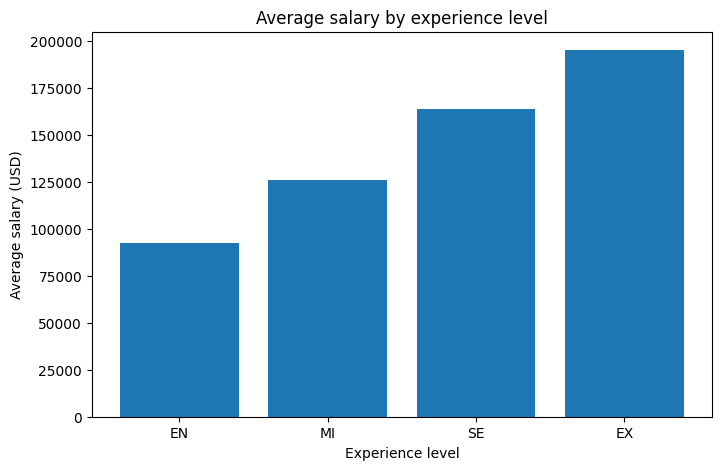

Average salary by experience level:
  EN: $92,327
  MI: $125,923
  SE: $163,663
  EX: $195,264

The highest average salary is in EX at $195,264.


In [30]:
order = ['EN', 'MI', 'SE', 'EX']
avg_salary = df.groupby('experience_level')['salary_in_usd'].mean().reindex(order)

plt.figure(figsize=(8, 5))
plt.bar(avg_salary.index, avg_salary.values)
plt.xlabel('Experience level')
plt.ylabel('Average salary (USD)')
plt.title('Average salary by experience level')
plt.show()

print("Average salary by experience level:")
for level, value in avg_salary.items():
    print(f"  {level}: ${value:,.0f}")
print(f"\nThe highest average salary is in {avg_salary.idxmax()} at ${avg_salary.max():,.0f}.")

**Task 9 — Scatter plot.** Make a scatter plot of `work_year` against `salary_in_usd`. Label the axes. What patterns do you notice? Are any points difficult to distinguish because they overlap?

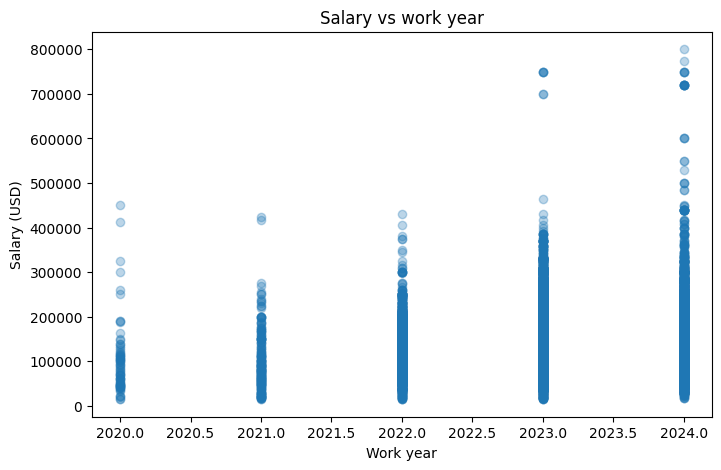

Number of records per year:
work_year
2020      75
2021     218
2022    1655
2023    8519
2024    6067

Average salary per year:
  2020: $102,251
  2021: $99,922
  2022: $134,350
  2023: $153,733
  2024: $150,564


In [31]:
plt.figure(figsize=(8, 5))
plt.scatter(df['work_year'], df['salary_in_usd'], alpha=0.3)
plt.xlabel('Work year')
plt.ylabel('Salary (USD)')
plt.title('Salary vs work year')
plt.show()

print("Number of records per year:")
print(df['work_year'].value_counts().sort_index().to_string())
print("\nAverage salary per year:")
for year, value in df.groupby('work_year')['salary_in_usd'].mean().items():
    print(f"  {year}: ${value:,.0f}")

**Task 10 — Distribution.** Plot the distribution of `salary_in_usd`. Does it look approximately normal, skewed, or something else? Are there extreme values?

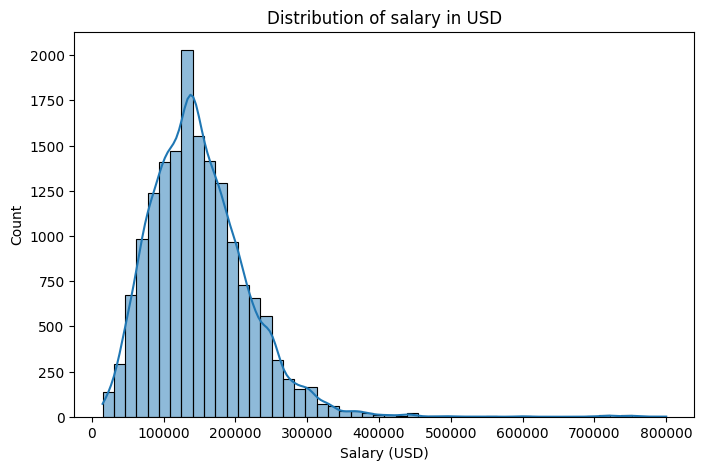

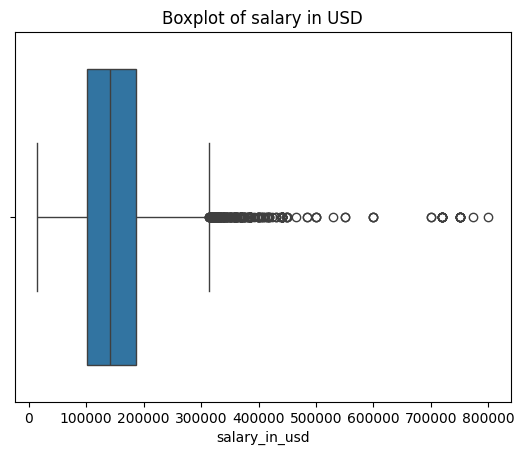

Skewness: 1.49 (above 0 means right-skewed)
Salaries above $313,062 count as outliers.
Number of outliers: 283


In [32]:
plt.figure(figsize=(8, 5))
sns.histplot(df['salary_in_usd'], bins=50, kde=True)
plt.xlabel('Salary (USD)')
plt.ylabel('Count')
plt.title('Distribution of salary in USD')
plt.show()

sns.boxplot(x=df['salary_in_usd'])
plt.title('Boxplot of salary in USD')
plt.show()

q1 = df['salary_in_usd'].quantile(0.25)
q3 = df['salary_in_usd'].quantile(0.75)
limit = q3 + 1.5 * (q3 - q1)
print(f"Skewness: {df['salary_in_usd'].skew():.2f} (above 0 means right-skewed)")
print(f"Salaries above ${limit:,.0f} count as outliers.")
print(f"Number of outliers: {(df['salary_in_usd'] > limit).sum()}")

**Task 11 — Pairwise relationships.** Visualize pairwise relationships among `salary_in_usd`, `work_year`, and `remote_ratio`, including distributions of the individual variables.

Try to compare the variables in one combined visualization. What relationships or patterns do you notice?

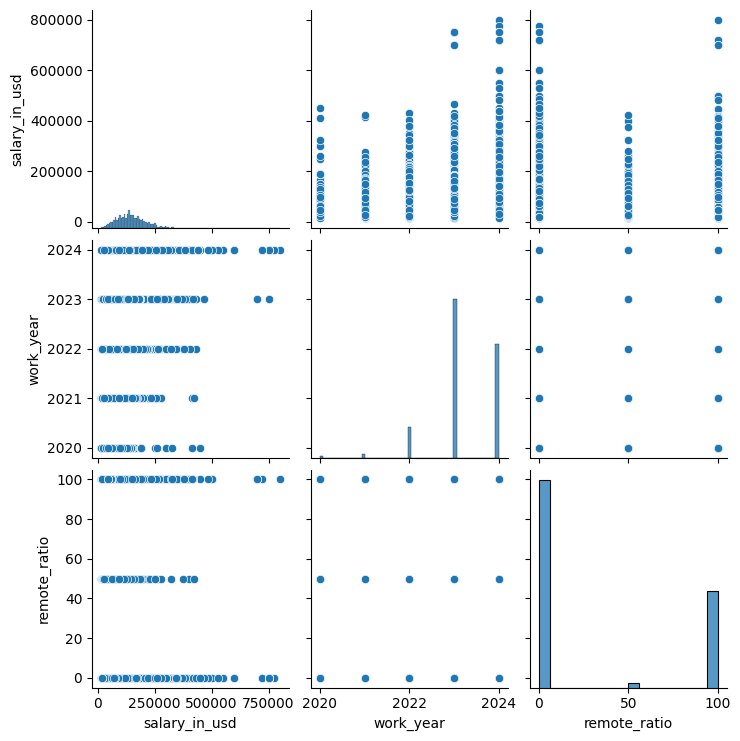

Correlation between the three variables:

               salary_in_usd  work_year  remote_ratio
salary_in_usd           1.00       0.08         -0.06
work_year               0.08       1.00         -0.20
remote_ratio           -0.06      -0.20          1.00


In [33]:
sns.pairplot(df[['salary_in_usd', 'work_year', 'remote_ratio']], diag_kind='hist')
plt.show()

print("Correlation between the three variables:\n")
print(df[['salary_in_usd', 'work_year', 'remote_ratio']].corr().round(2))

**Task 12 — Remove a column.** Remove the original-currency `salary` column while retaining `salary_in_usd`, then inspect the updated DataFrame. Why might you choose to keep one salary column rather than both?

In [34]:
df = df.drop(columns=['salary'])
print(f"The 'salary' column has been removed. The dataset now has {df.shape[1]} columns:\n")
print(list(df.columns))
df.head()

The 'salary' column has been removed. The dataset now has 10 columns:

['work_year', 'experience_level', 'employment_type', 'job_title', 'salary_currency', 'salary_in_usd', 'employee_residence', 'remote_ratio', 'company_location', 'company_size']


,work_year,experience_level,employment_type,job_title,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2024,SE,FT,AI Engineer,USD,202730,US,0,US,M
1,2024,SE,FT,AI Engineer,USD,92118,US,0,US,M
2,2024,SE,FT,Data Engineer,USD,130500,US,0,US,M
3,2024,SE,FT,Data Engineer,USD,96000,US,0,US,M
4,2024,SE,FT,Machine Learning Engineer,USD,190000,US,0,US,M


**Reflection.** What have you learned about the salary dataset? Which additional checks or visualizations would be useful before building a machine learning model?

Well done!

## Reflection

### What I learned about the dataset

The dataset has **16,534 rows and 11 columns**, with **no missing values**, so little cleaning is needed. It does contain **6,421 duplicate rows**. These are probably not errors: there is no employee ID, so two people with the same job, experience level, year and location could easily report the same salary.

The data is heavily weighted towards certain groups:

- Most records are from **2023 and 2024**.
- Most employees are **senior level** (10,670 records).
- Most salaries are paid in **USD**.
- There are only **501 executives** and **249 hybrid workers**, so conclusions about these groups are less reliable.

`salary_in_usd` is **right-skewed**. The mean (about **\$149,700**) is higher than the median (**\$141,300**), and **283 salaries** are extreme values above roughly \$313,000. Pay rises clearly with experience, from about **\$92,000** for entry level to **\$195,000** for executives. In contrast, `work_year` and `remote_ratio` have almost no linear relationship with salary.

The original `salary` column mixed currencies, so I removed it and kept `salary_in_usd`.

### Checks and visualisations before building a model

1. **Treat the skew:** apply a log transformation to `salary_in_usd`, and decide whether to keep, cap or remove the extreme values.
2. **Duplicates:** decide whether to keep them, and test how removing them changes the results.
3. **Class imbalance:** check that experience level, company location and remote ratio have enough examples in each category.
4. **Encoding:** convert categorical columns (`experience_level`, `job_title`, `company_size`, `company_location`) into numbers, for example with one-hot encoding. Rare job titles and locations could be grouped into an "Other" category.
5. **Further visualisations:**
   - Boxplots of salary by company size, employment type and job title
   - Average salary by company location
   - A correlation heatmap after encoding
6. **Data leakage and fairness:** make sure no feature indirectly reveals salary, and check whether the model only works well for US-based senior employees, since they dominate the data.